In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


# 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/"


In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [7]:
from hmm_logic_methods import load_model
total_splits = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]])
MODEL_PREFIX_TO_READ = [ "8-9-mer-frozen-fair"]
BAUM_WELCH_MODELS = [f"{i}_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches" for i in range(5)]
VITERBI_MODELS = [f"{i}_run-8-mer-12-st-viterbi-0.0-lr-None-inertia-None-batches" for i in range(5)]

MODEL_PREFIX_TO_READ = BAUM_WELCH_MODELS + VITERBI_MODELS

per_name_model = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for model_to_read in MODEL_PREFIX_TO_READ:
            for split_num in range(total_splits):
                model_name = f"{model_to_read}_model-{target_allele_name}-{split_num}"
                model = load_model(TARGET_PATH_TO_RESULTS, model_name)
                per_name_model[model_name] = model
                # print(model_name)

# 3. Visualize
## 3.1 State graph

In [8]:
from hmm_visualization_methods import *

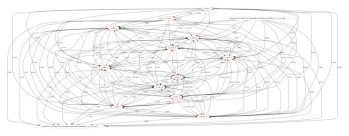

In [6]:
for model in per_name_model.values():
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
        model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

## 3.2 Distributions for states

In [7]:
%%time

for model in per_name_model.values():
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)

in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormal

## 3.3 States graph visualization (Based on previous point)

In [9]:
per_name_pyviz = dict()
for name, model in per_name_model.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS)

Model: 0_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0
0_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0-start -> s0_run-8_1 1.0 2
s0_run-8_1 -> s0_run-8_8 1.0 3
s0_run-8_8 -> s0_run-8_5 0.982 4
s0_run-8_8 -> s0_run-8_10 0.018 4
s0_run-8_10 -> s0_run-8_7 1.0 5
s0_run-8_7 -> s0_run-8_4 0.1829 6
s0_run-8_7 -> s0_run-8_9 0.8171 6
s0_run-8_9 -> s0_run-8_11 1.0 7
s0_run-8_11 -> s0_run-8_3 0.4799 8
s0_run-8_11 -> s0_run-8_6 0.5201 8
s0_run-8_6 -> s0_run-8_0 0.0009 9
s0_run-8_6 -> s0_run-8_2 0.9991 9
s0_run-8_2 -> 0_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0-end 1.0 10
{'0_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0-start': 1, 's0_run-8_1': 2, 's0_run-8_8': 3, 's0_run-8_5': 4, 's0_run-8_10': 4, 's0_run-8_7': 5, 's0_run-8_4': 6, 's0_run-8_9': 6, 's0_run-8_11': 7, 's0_run-8_3': 8, 's0_run-8_6': 8, 's0_run-8_0': 9, 's0_run-8_2': 9, '0_run-8-mer-12-st-baum-wel

In [48]:
sample_model = per_name_model["0_run-8-mer-12-st-viterbi-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-1"]

In [49]:
from pomegranate.base import State
for sample_input in per_allele_per_kfold_per_length_binders_test[ALLELES[0]][1][8]:
    sequence = list(sample_input)
    logp, path = sample_model.viterbi(sequence)
    first_state = path[0][1]
    # if type(first_state) != State:
    #     print(first_state)
    #     print(logp, path)
    if first_state.name != sample_model.start.name:
        print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[0:-1] ) ))
        logp, path = sample_model.maximum_a_posteriori(sequence)

        print("Max a post for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))


In [42]:
sample_model = per_name_model["0_run-8-mer-12-st-baum-welch-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-1"]

In [50]:
sample_model.bake(verbose=True)

In [51]:
sample_model.start_index

12

In [53]:
sample_model.states

[{
     "class" : "State",
     "distribution" : {
         "class" : "Distribution",
         "dtype" : "str",
         "name" : "DiscreteDistribution",
         "parameters" : [
             {
                 "A" : 0.0,
                 "C" : 0.0,
                 "D" : 0.0,
                 "E" : 0.0,
                 "F" : 0.0,
                 "G" : 0.0,
                 "H" : 0.0,
                 "I" : 0.0,
                 "K" : 0.0,
                 "L" : 0.0,
                 "M" : 0.0,
                 "N" : 0.18890248878008975,
                 "P" : 0.0,
                 "Q" : 0.0,
                 "R" : 0.0,
                 "S" : 0.0,
                 "T" : 0.0,
                 "V" : 0.8110975112199102,
                 "W" : 0.0,
                 "Y" : 0.0
             }
         ],
         "frozen" : false
     },
     "name" : "s0_run-8_0",
     "weight" : 1.0
 },
 {
     "class" : "State",
     "distribution" : {
         "class" : "Distribution",
         "dtype"

In [52]:
sample_model.dense_transition_matrix()

array([[0.10811914, 0.        , 0.08853529, 0.00693594, 0.02896777,
        0.07670339, 0.12974296, 0.04243166, 0.04120767, 0.124847  ,
        0.07058344, 0.03671971, 0.        , 0.24520604],
       [0.07692308, 0.07692308, 0.07692308, 0.07692308, 0.07692308,
        0.07692308, 0.07692308, 0.07692308, 0.07692308, 0.07692308,
        0.07692308, 0.07692308, 0.        , 0.07692308],
       [0.15543071, 0.        , 0.09456929, 0.00561798, 0.02996255,
        0.06273408, 0.15496255, 0.04775281, 0.03932584, 0.1994382 ,
        0.09316479, 0.03604869, 0.        , 0.08099251],
       [0.0952381 , 0.        , 0.0952381 , 0.        , 0.02040816,
        0.08843537, 0.14285714, 0.05442177, 0.03401361, 0.13605442,
        0.16326531, 0.06122449, 0.        , 0.10884354],
       [0.14851485, 0.        , 0.09193777, 0.00990099, 0.03960396,
        0.06364922, 0.15558699, 0.06364922, 0.02121641, 0.17538897,
        0.09335219, 0.04384724, 0.        , 0.09335219],
       [0.13987932, 0.        , 0.1

In [17]:
sample_input = 'CCC'
sequence = list(sample_input)
logp, path = sample_model.viterbi(sequence)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[0:-1] ) ))
logp, path = sample_model.maximum_a_posteriori(sequence)

print("Max a post for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))


TypeError: 'NoneType' object is not subscriptable

In [10]:
[state.name for state in model.states]

['s0_run-8_0',
 's0_run-8_1',
 's0_run-8_10',
 's0_run-8_11',
 's0_run-8_2',
 's0_run-8_3',
 's0_run-8_4',
 's0_run-8_5',
 's0_run-8_6',
 's0_run-8_7',
 's0_run-8_8',
 's0_run-8_9',
 '0_run-8-mer-12-st-viterbi-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0-start',
 '0_run-8-mer-12-st-viterbi-0.0-lr-None-inertia-None-batches_model-HLA_A_02_01-0-end']

## 3.4 Logo for sequences

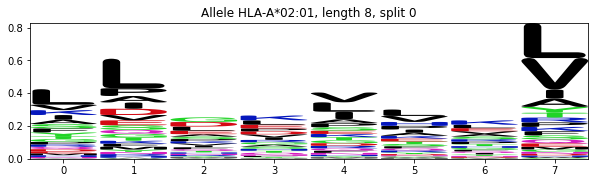

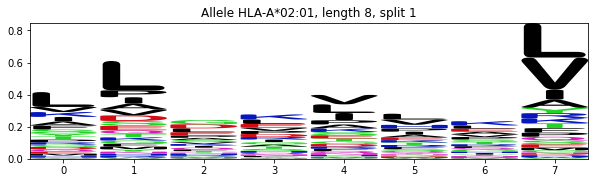

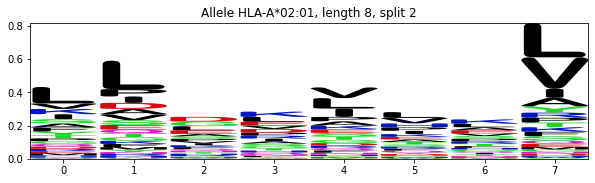

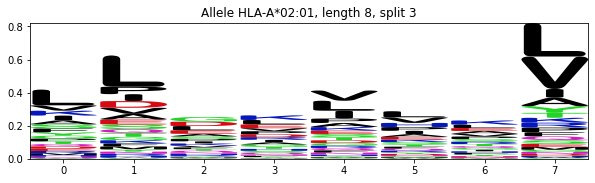

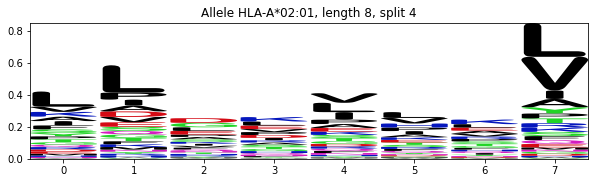

In [5]:
make_logos_for_train_sequences(8, per_allele_per_kfold_per_length_binders_train, TARGET_PATH_TO_RESULTS)